# Midterm-project 

In [36]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score,mean_squared_error




In [37]:
print(pd.__version__)

3.0.5


In [38]:

df = pd.read_csv("./energydata_complete.csv")
pd.set_option('display.max_columns', None)

df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


## EDA

In [39]:
df.info()#Check the number of rows and columns, identify datatypes 

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

In [40]:
df.isnull().sum() #check if the colomn having a missing value. No missing value 

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [41]:
#Search for duplicate rows.
duplicates = df[df.duplicated(keep=False)]

print("=== Lignes dupliquées ===")
print(duplicates)

df.duplicated(subset=["date"]).sum()

=== Lignes dupliquées ===
Empty DataFrame
Columns: [date, Appliances, lights, T1, RH_1, T2, RH_2, T3, RH_3, T4, RH_4, T5, RH_5, T6, RH_6, T7, RH_7, T8, RH_8, T9, RH_9, T_out, Press_mm_hg, RH_out, Windspeed, Visibility, Tdewpoint, rv1, rv2]
Index: []


np.int64(0)

In [42]:
df ['date'] = pd.to_datetime(df['date']) #converte column 'date' from string to datetime type 
print(df["date"].dtype)

datetime64[us]


In [43]:
#to have the start and end dates 
date_debut= df['date'].min()
date_fin = df['date'].max()

print("Date de debut :", date_debut)
print("Date de fin :", date_fin)

Date de debut : 2016-01-11 17:00:00
Date de fin : 2016-05-27 18:00:00


In [44]:
#Check that the dates are arranged in chronological order.
ordre_chronologique= df['date'].is_monotonic_increasing
print(f"Are the dates listed in chronological order? {ordre_chronologique}")


Are the dates listed in chronological order? True


In [45]:
#Check to see if all the measurements are spaced 10 minutes apart.
    # Sort by chronological order (important for verification)
df =df.sort_values('date').reset_index(drop=True)
    # Calculating the Differences Between Measurements
time_diffs =df["date"].diff().dropna()
    # Verification: All the differences are exactly 10 minutes
expected_interval = pd.Timedelta(minutes=10)
all_ok =(time_diffs == expected_interval).all()
if all_ok:
    print("Toutes les mesures sont espacé de 10minutes")
else:
    print("certaines mesures ne respectentn pas l'espassement de 10 minutes")




Toutes les mesures sont espacé de 10minutes


In [46]:
#Generate a summary of descriptives statistics
summary_stats = df.describe()
print("Describe Statistics summary:")
print(summary_stats)


Describe Statistics summary:
                             date    Appliances        lights            T1  \
count                       19735  19735.000000  19735.000000  19735.000000   
mean   2016-03-20 05:29:59.999999     97.694958      3.801875     21.686571   
min           2016-01-11 17:00:00     10.000000      0.000000     16.790000   
25%           2016-02-14 23:15:00     50.000000      0.000000     20.760000   
50%           2016-03-20 05:30:00     60.000000      0.000000     21.600000   
75%           2016-04-23 11:45:00    100.000000      0.000000     22.600000   
max           2016-05-27 18:00:00   1080.000000     70.000000     26.260000   
std                           NaN    102.524891      7.935988      1.606066   

               RH_1            T2          RH_2            T3          RH_3  \
count  19735.000000  19735.000000  19735.000000  19735.000000  19735.000000   
mean      40.259739     20.341219     40.420420     22.267611     39.242500   
min       27.023333   

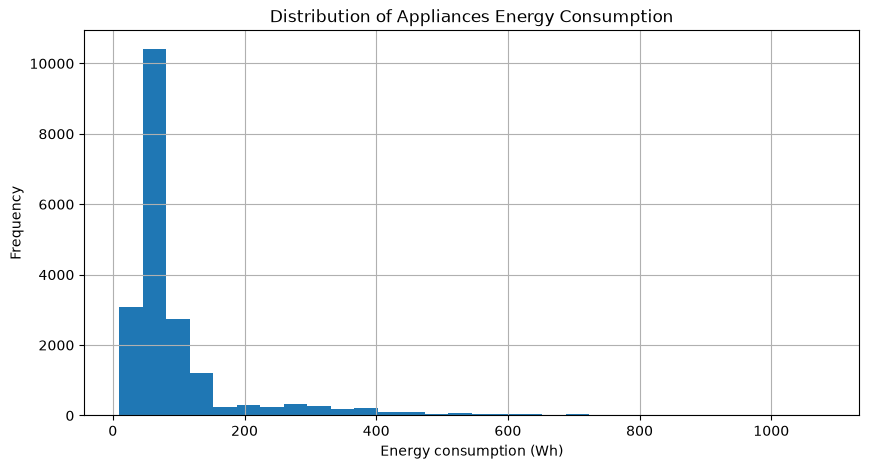

In [47]:
#plot histogramme 
df.hist(column='Appliances', bins=30, figsize=(10, 5))

plt.title("Distribution of Appliances Energy Consumption")
plt.xlabel("Energy consumption (Wh)")
plt.ylabel("Frequency")
plt.show()

In [48]:
"""Target Variable Analysis - Appliances

The distribution of the target variable `Appliances` is strongly right-skewed. Most observations correspond to low energy consumption, while a small number show significantly higher values.

The mean consumption is approximately 97.69 Wh, whereas the median is 60 Wh, indicating that high consumption values influence the average.

The maximum recorded consumption is 1,080 Wh.

These high values should not be automatically removed, as they may represent real consumption peaks. Their impact on model performance will be evaluated using MAE and RMSE."""

'Target Variable Analysis - Appliances\n\nThe distribution of the target variable `Appliances` is strongly right-skewed. Most observations correspond to low energy consumption, while a small number show significantly higher values.\n\nThe mean consumption is approximately 97.69 Wh, whereas the median is 60 Wh, indicating that high consumption values influence the average.\n\nThe maximum recorded consumption is 1,080 Wh.\n\nThese high values should not be automatically removed, as they may represent real consumption peaks. Their impact on model performance will be evaluated using MAE and RMSE.'

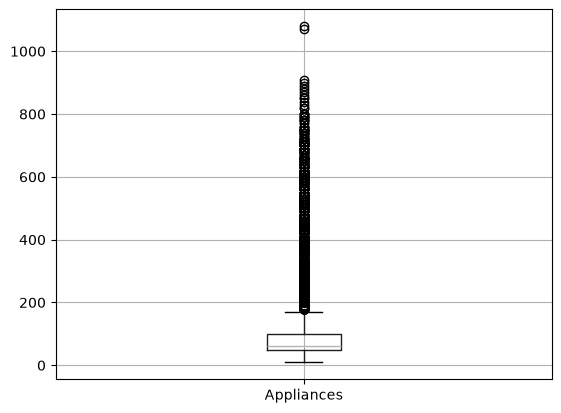

In [49]:
boxplot = df.boxplot(column="Appliances")

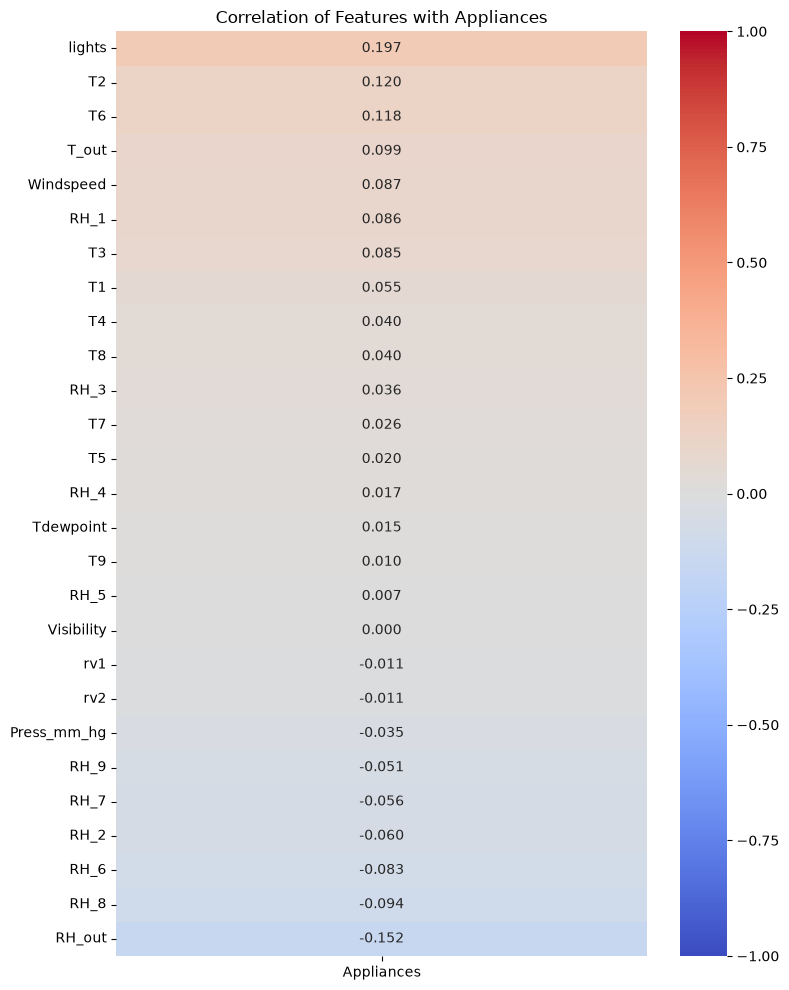

In [50]:
#Evaluate a correlation between variableimport seaborn as sns
import matplotlib.pyplot as plt

correlations = (
    df.corr(numeric_only=True)["Appliances"]
    .drop("Appliances")
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 10))

sns.heatmap(
    correlations.to_frame(),
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation of Features with Appliances")
plt.tight_layout()
plt.show()

### EDA Conclusion

The Appliances Energy Prediction dataset contains 19,735 observations and 29 columns, with no missing values or duplicated records. The measurements are recorded every 10 minutes and are chronologically ordered.

The target variable, `Appliances`, has a strongly right-skewed distribution, with an average consumption of 97.69 Wh and a median of 60 Wh. High consumption values were identified but retained, as they may represent genuine energy consumption peaks.

The correlation analysis shows generally weak linear relationships between individual features and the target variable.

The dataset is suitable for regression modeling. Linear Regression, Random Forest and XGBoost will be compared to evaluate their ability to predict appliance energy consumption.

## Split and Model training 

In [51]:
# Convert date to datetime
df['date'] = pd.to_datetime(df['date'])

# Extract hour and minutes
hour = df['date'].dt.hour + df['date'].dt.minute / 60

# Create cyclical hour features
df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * hour / 24)

In [52]:
#Split the data:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [53]:
# Define features and target
features = [
    'lights', 'T1', 'T2', 'T3',
    'T4', 'T5', 'T6', 'T7',
    'T8', 'T9', 'T_out', 'RH_1',
    'RH_2', 'RH_3', 'RH_4', 'RH_5',
    'RH_6', 'RH_7', 'RH_8', 'RH_9',
    'RH_out', 'Press_mm_hg', 'Windspeed',
    'Visibility', 'Tdewpoint',
    'hour_sin', 'hour_cos'
]

target = 'Appliances'

# Define target values
y_train = df_train[target].values
y_test = df_test[target].values
y_true = df_val[target].values

In [54]:
   #Train ridge regressor 
def train(df_train, y_train, a=1):
    X_train = df_train[features]
          #Normalisation 
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    ridge_model = Ridge(alpha=a)  
    ridge_model.fit(X_train_scaled, y_train)
    
    return scaler, ridge_model
# Make a Prediction 

def predict(df, scaler, ridge_model):
    X = df[features]
    X_scaled = scaler.transform(X)
    y_pred = ridge_model.predict(X_scaled)
    return y_pred

scaler, ridge_model = train(df_train, y_train)#train 
y_val_pred = predict(df_val, scaler, ridge_model)#prediction 
#print metrics
mae = mean_absolute_error(y_true, y_val_pred)
rmse = root_mean_squared_error(y_true, y_val_pred)
r2 = r2_score(y_true, y_val_pred)
print("Ridge regressor ")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

Ridge regressor 
MAE: 51.27313521180296
RMSE: 90.76783411604637
R²: 0.17909226781222742


In [55]:
    #Train Randomforestregressor     
def Rtrain(df_train, y_train,n=300, r=42):
    X_train = df_train[features]
    rf = RandomForestRegressor(n_estimators=n, max_depth=None, random_state=r)
    rf.fit(X_train, y_train)
    return rf

# Make a prediction
def Rpredict(df, rf):
    X = df[features]
    y_pred = rf.predict(X)
    return y_pred

rf = Rtrain(df_train, y_train)
y_val_pred = Rpredict(df_val, rf)

mae = mean_absolute_error(y_true, y_val_pred)
rmse = root_mean_squared_error(y_true, y_val_pred)
r2 = r2_score(y_true, y_val_pred)
print("Random forest")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

Random forest
MAE: 33.01790389325226
RMSE: 68.34207033196904
R²: 0.5346211271991096


In [56]:
     #Train XGBOOST REGRESSOR 
params = {
    "n_estimators": 500,
    "max_depth": 6,
    "min_child_weight": 5,
    "learning_rate": 0.01
}

def Gtrain(df_train, y_train, params):
    X_train = df_train[features]
    xg_model = XGBRegressor(**params, random_state=42)
    xg_model.fit(X_train, y_train)
    return xg_model

# Make a Prediction
def Gpredict(df, xg_model):
    X = df[features]
    y_pred = xg_model.predict(X)
    return y_pred

xg_model = Gtrain(df_train, y_train, params)
y_val_pred = Gpredict(df_val, xg_model)

mae = mean_absolute_error(y_true, y_val_pred)
rmse = root_mean_squared_error(y_true, y_val_pred)
r2 = r2_score(y_true, y_val_pred)
print("XGBOOST regressor")
print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

XGBOOST regressor
MAE: 39.121944427490234
RMSE: 76.01795959472656
R²: 0.42421168088912964


In [57]:

# 1. PREDICTIONS ON VALIDATION DATA

predictions = {
    "Ridge": predict(df_val, scaler, ridge_model),
    "Random Forest": Rpredict(df_val, rf),
    "XGBoost": Gpredict(df_val, xg_model)
}

# 2. EVALUATION FUNCTION


def metrics(y_true, predictions):
    scores = {}

    for name, y_pred in predictions.items():

        # Calculate MAE
        mae = mean_absolute_error(y_true, y_pred)

        # Calculate RMSE
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))

        # Calculate R²
        r2 = r2_score(y_true, y_pred)

        scores[name] = {
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        }

    return pd.DataFrame(scores).T

# 3. COMPARE THE THREE MODELS

y_val = df_val[target].values
results = metrics(y_val, predictions)
display(results.sort_values(by="MAE").round(4))
    

,MAE,RMSE,R2
Random Forest,33.0179,68.3421,0.5346
XGBoost,39.1219,76.0180,0.4242
Ridge,51.2731,90.7678,0.1791


In [58]:

#Predictions on test data


test_predictions = {
    "Ridge": predict(df_test, scaler, ridge_model),
    "Random Forest": Rpredict(df_test, rf),
    "XGBoost": Gpredict(df_test, xg_model)
}


# Evaluate models on test data

y_test = df_test[target].values

test_results = metrics(y_test, test_predictions)

# 3. Display comparative table

display(test_results.sort_values(by="MAE").round(4))

,MAE,RMSE,R2
Random Forest,31.8628,66.8830,0.5530
XGBoost,39.6614,76.9879,0.4077
Ridge,51.9404,89.5636,0.1984


### Final Conclusion — Model Training, Hyperparameter Tuning and Feature Engineering

Three regression models were trained and compared: **Ridge Regression, Random Forest Regressor, and XGBoost Regressor**, using MAE, RMSE, and R² as evaluation metrics.

Hyperparameter tuning was performed to improve model performance:

- **Ridge Regression:** Three alpha values (0.5, 1.0, and 5.0) were tested, with no significant changes in performance.
- **Random Forest:** Six configurations were evaluated. The best results were obtained with 300 estimators, `max_depth=None`, and `random_state=42`.
- **XGBoost:** Three configurations were tested by adjusting the number of estimators and tree depth. Performance improved, but remained below Random Forest.

An additional feature engineering experiment was conducted by introducing two cyclical time features: `hour_sin` and `hour_cos`.

This experiment improved Random Forest's validation performance:

| Metric | Without Hour | With Hour |
|---|---|---|
| MAE | 35.53 Wh | **33.01 Wh** |
| RMSE | 73.29 Wh | **68.34 Wh** |
| R² | 0.4648 | **0.5346** |

**Final Decision:** Random Forest Regressor with 300 estimators and cyclical hour features was selected as the most promising model. It achieved the best validation performance among the tested approaches.

The next steps are feature importance analysis, final model evaluation, and deployment.

#### Save the model 

In [59]:
import pickle 

In [60]:
output_file  = 'model_rfr' #random foreste regressor =rfr

In [61]:
output_file 

'model_rfr'

In [62]:
with open(output_file, 'wb') as f_out:
    pickle.dump(rf, f_out)
print(f"Model saved sucessfuly: {output_file}")
            

Model saved sucessfuly: model_rfr


#### Load the model 

In [63]:
import pickle 

In [64]:
input_file = 'model_rfr'

In [65]:
with open (input_file, 'rb') as f_in:
    rfr_loaded=pickle.load(f_in)

In [66]:
print ("Model loaded successfully!")
print ("Model:", type(rfr_loaded). __name__)
print ("Number of features:", rfr_loaded.n_features_in_)

Model loaded successfully!
Model: RandomForestRegressor
Number of features: 27


In [67]:
# Make predictions using the loaded model
y_pred_loaded = Rpredict(df_val, rfr_loaded)

# Evaluate
mae = mean_absolute_error(y_true, y_pred_loaded)
rmse = root_mean_squared_error(y_true, y_pred_loaded)
r2 = r2_score(y_true, y_pred_loaded)

print("Loaded Random Forest model")
print("MAE(Wh):", mae)
print("RMSE(Wh):", rmse)
print("R²(Wh):", r2)

"""In summary: `rf` is used to train and save your model; 
`rfr_loaded` is used to reuse it to make predictions without retraining."""

Loaded Random Forest model
MAE(Wh): 33.01790389325226
RMSE(Wh): 68.34207033196904
R²(Wh): 0.5346211271991096


'In summary: `rf` is used to train and save your model; \n`rfr_loaded` is used to reuse it to make predictions without retraining.'

In [68]:
house = {
    'date': '2016-04-10 18:00:00',
    'lights': 10,
    'T1': 21.5,
    'T2': 20.8,
    'T3': 22.1,
    'T4': 20.5,
    'T5': 19.5,
    'T6': 8.2,
    'T7': 20.3,
    'T8': 22.0,
    'T9': 19.5,
    'T_out': 9.0,
    'RH_1': 40.5,
    'RH_2': 42.0,
    'RH_3': 39.5,
    'RH_4': 38.0,
    'RH_5': 50.0,
    'RH_6': 55.0,
    'RH_7': 35.5,
    'RH_8': 43.0,
    'RH_9': 41.0,
    'RH_out': 75.0,
    'Press_mm_hg': 755.0,
    'Windspeed': 3.5,
    'Visibility': 40.0,
    'Tdewpoint': 4.0
}

In [69]:
# Convert dictionary to DataFrame
house_df = pd.DataFrame([house])

# Create hour features
date = pd.to_datetime(house_df['date'])
hour = date.dt.hour + date.dt.minute / 60

house_df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
house_df['hour_cos'] = np.cos(2 * np.pi * hour / 24)

# Use the same features and order as training
X_house = house_df[rfr_loaded.feature_names_in_]

# Predict energy consumption
prediction = rfr_loaded.predict(X_house)

print(f"Predicted energy consumption: {prediction[0]:.2f} Wh")

Predicted energy consumption: 167.33 Wh


#### Making request

In [76]:
import requests

In [77]:
url = 'http://localhost:9696/predict'

In [2]:
house = {
    'date': '2016-04-10 18:00:00',
    'lights': 10,
    'T1': 21.5,
    'T2': 20.8,
    'T3': 22.1,
    'T4': 20.5,
    'T5': 19.5,
    'T6': 8.2,
    'T7': 20.3,
    'T8': 22.0,
    'T9': 19.5,
    'T_out': 9.0,
    'RH_1': 40.5,
    'RH_2': 42.0,
    'RH_3': 39.5,
    'RH_4': 38.0,
    'RH_5': 50.0,
    'RH_6': 55.0,
    'RH_7': 35.5,
    'RH_8': 43.0,
    'RH_9': 41.0,
    'RH_out': 75.0,
    'Press_mm_hg': 755.0,
    'Windspeed': 3.5,
    'Visibility': 40.0,
    'Tdewpoint': 4.0
}

In [79]:
response = requests.post(url, json=house, timeout=30)

print("HTTP Status:", response.status_code)

result = response.json()

print(result)

HTTP Status: 200
{'Energy': 167.33333333333334}


In [3]:
import json

with open(
    "/workspaces/MLDTC_homework1/Midterm-project/Energy-prediction/house.json",
    "w"
) as f:
    json.dump(house, f, indent=4)